<a href="https://colab.research.google.com/github/sjadhav7279-boop/AI-ML-Assignments/blob/main/Assignment3(dashmart).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
raw = pd.read_csv("dashmart_delivery_times_raw.csv", dtype=str)
print(raw.shape)                                    # Q1: (2430, 11)

def pattern(s):                                     # '8 PM' -> '9 a', '0:15:18' -> '9:9:9'
    return re.sub(r"[A-Za-z]+", "a", re.sub(r"\d+", "9", str(s)))
for c in ["order_hour", "distance_km", "delivery_minutes"]:
    print(c, raw[c].map(pattern).value_counts().to_dict())

df = raw.copy()

In [3]:
df["store"] = (df["store"].str.strip().str.lower()
               .str.replace(r"^dm[\s-]+", "", regex=True).str.title())

def to_hour(s):
    s = str(s).strip().upper()
    m = re.match(r"^(\d{1,2})\s*(AM|PM)$", s)
    if m: return int(m.group(1)) % 12 + (12 if m.group(2) == "PM" else 0)
    m = re.match(r"^(\d{1,2}):\d{2}$", s)
    if m: return int(m.group(1))
    return int(float(s))
df["order_hour"] = df["order_hour"].map(to_hour)

In [3]:
def to_km(s):
    s = str(s).strip().lower()
    m = re.match(r"^([\d.]+)\s*km$", s)
    if m: return float(m.group(1))
    m = re.match(r"^([\d.]+)\s*m$", s)
    if m: return float(m.group(1)) / 1000
    return float(s)
df["distance_km"] = df["distance_km"].map(to_km)


In [4]:
def to_min(s):
    s = str(s).strip().lower()
    m = re.match(r"^(\d+):(\d{2}):(\d{2})$", s)           # h:mm:ss
    if m: return int(m.group(1))*60 + int(m.group(2)) + int(m.group(3))/60
    m = re.match(r"^(-?[\d.]+)\s*min$", s)
    if m: return float(m.group(1))
    return float(s)
df["delivery_minutes"] = df["delivery_minutes"].map(to_min)
bad = (df["delivery_minutes"] <= 0) | (df["delivery_minutes"] > 120)
print(df.loc[bad, ["order_id", "delivery_minutes"]])
df = df[~bad]

In [5]:
df["raining"] = df["raining"].str.strip().str.lower().map(
    {"y":1,"yes":1,"true":1,"1":1,"n":0,"no":0,"false":0,"0":0})
df["order_value_rs"] = pd.to_numeric(df["order_value_rs"].str.replace("[₹,]", "", regex=True))
df["rider_experience_months"] = pd.to_numeric(
    df["rider_experience_months"].replace({"new joiner": "0"}), errors="coerce")
df["store_queue"] = pd.to_numeric(df["store_queue"], errors="coerce")    # '?' -> NaN
for c in ["items", "drop_floor"]: df[c] = pd.to_numeric(df[c])
print("before dedup:", len(df)); df = df.drop_duplicates().reset_index(drop=True)
print("after dedup: ", len(df))

after dedup:  2421


In [6]:
print(df.isna().sum())

order_id                    0
store                       0
order_hour                  0
distance_km                 0
items                       0
order_value_rs              0
store_queue                18
raining                     0
rider_experience_months    44
drop_floor                  0
delivery_minutes            0
dtype: int64


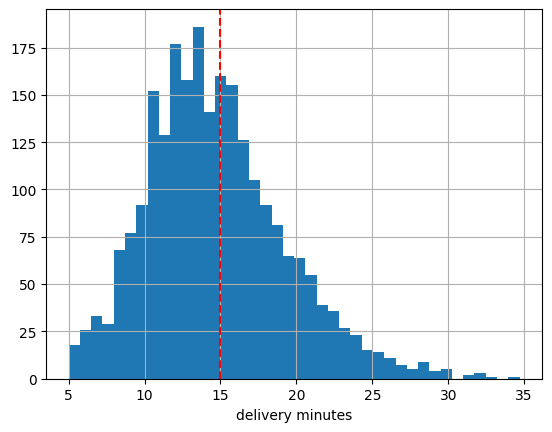

In [7]:
d = df["delivery_minutes"]
print(d.median(), d.mean(), (d > 15).mean(), (d[d > 15] - 15).mean())
d.hist(bins=40); plt.axvline(15, color="red", ls="--"); plt.xlabel("delivery minutes"); plt.show()

In [7]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error, r2_score
RMSE = lambda a, b: mean_squared_error(a, b) ** 0.5

feats = ["distance_km","items","order_value_rs","store_queue","raining",
         "rider_experience_months","drop_floor","order_hour"]
X, y = df[feats], df["delivery_minutes"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def make(scaler=None, k=7, **kw):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scaler: steps.append(("sc", scaler))
    return Pipeline(steps + [("knn", KNeighborsRegressor(n_neighbors=k, **kw))])


In [7]:
base = np.full(len(y_test), y_train.median())
print(MAE(y_test, base))


In [7]:
rows = []
for name, sc in [("raw", None), ("standard", StandardScaler()), ("minmax", MinMaxScaler())]:
    p = make(sc).fit(X_train, y_train).predict(X_test)
    rows.append([name, MAE(y_test, p), RMSE(y_test, p), r2_score(y_test, p)])
print(pd.DataFrame(rows, columns=["model", "MAE", "RMSE", "R2"]).round(3))
print(X_train.std())                       # shows who dominates the raw distance
print(df.corr(numeric_only=True)["delivery_minutes"])


In [7]:
kf = KFold(5, shuffle=True, random_state=42)
ks = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
cv_mae = [-cross_val_score(make(StandardScaler(), k), X_train, y_train, cv=kf,
          scoring="neg_mean_absolute_error").mean() for k in ks]
plt.plot(ks, cv_mae, marker="o"); plt.xlabel("k"); plt.ylabel("CV MAE"); plt.show()


In [7]:
def add_cyc(D):
    D = D.copy()
    D["hour_sin"] = np.sin(2*np.pi*D.order_hour/24)
    D["hour_cos"] = np.cos(2*np.pi*D.order_hour/24)
    return D.drop(columns="order_hour")
night = X_test.order_hour.isin([23, 0, 1]).values            # 23:00-01:59
p_raw = make(StandardScaler()).fit(X_train, y_train).predict(X_test)
p_cyc = make(StandardScaler()).fit(add_cyc(X_train), y_train).predict(add_cyc(X_test))
print(MAE(y_test, p_raw), MAE(y_test, p_cyc))
print(MAE(y_test[night], p_raw[night]), MAE(y_test[night], p_cyc[night]), night.sum())


In [7]:
gs = GridSearchCV(make(StandardScaler()),
                  {"knn__n_neighbors": list(range(1, 52, 2)), "knn__weights": ["uniform", "distance"]},
                  scoring="neg_mean_absolute_error", cv=kf, n_jobs=-1).fit(X_train, y_train)
best = gs.best_estimator_; pred = best.predict(X_test)
print(gs.best_params_, -gs.best_score_, MAE(y_test, pred), RMSE(y_test, pred), r2_score(y_test, pred))


In [9]:
# Q15: drop order_value_rs and re-run (scaled KNN, same grid as Q14)
f2 = [f for f in feats if f != "order_value_rs"]

gs2 = GridSearchCV(
    make(StandardScaler()),
    {"knn__n_neighbors": list(range(1, 52, 2)),
     "knn__weights": ["uniform", "distance"]},
    scoring="neg_mean_absolute_error", cv=kf, n_jobs=-1
).fit(X_train[f2], y_train)                      # <- this is the line that defines gs2

p2 = gs2.best_estimator_.predict(X_test[f2])

print("Best params:", gs2.best_params_)
print("CV MAE     :", -gs2.best_score_)
print("Test MAE   :", MAE(y_test, p2))
print("Test RMSE  :", RMSE(y_test, p2))
print("Test R2    :", r2_score(y_test, p2))

# side-by-side with the Q14 model (with order_value_rs)
print(pd.DataFrame({
    "with order_value_rs":    [-gs.best_score_,  MAE(y_test, pred), RMSE(y_test, pred), r2_score(y_test, pred)],
    "without order_value_rs": [-gs2.best_score_, MAE(y_test, p2),   RMSE(y_test, p2),   r2_score(y_test, p2)],
}, index=["CV MAE", "Test MAE", "Test RMSE", "Test R2"]).round(3))

NameError: name 'feats' is not defined

In [11]:
import re, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error, r2_score
RMSE = lambda a, b: mean_squared_error(a, b) ** 0.5

# ---------- cleaning (Q1-Q6) ----------
df = pd.read_csv("dashmart_delivery_times_raw.csv", dtype=str)   # change to your full path if needed

df["store"] = (df["store"].str.strip().str.lower()
               .str.replace(r"^dm[\s-]+", "", regex=True).str.title())

def to_hour(s):
    s = str(s).strip().upper()
    m = re.match(r"^(\d{1,2})\s*(AM|PM)$", s)
    if m: return int(m.group(1)) % 12 + (12 if m.group(2) == "PM" else 0)
    m = re.match(r"^(\d{1,2}):\d{2}$", s)
    if m: return int(m.group(1))
    return int(float(s))
df["order_hour"] = df["order_hour"].map(to_hour)

def to_km(s):
    s = str(s).strip().lower()
    m = re.match(r"^([\d.]+)\s*km$", s)
    if m: return float(m.group(1))
    m = re.match(r"^([\d.]+)\s*m$", s)
    if m: return float(m.group(1)) / 1000
    return float(s)
df["distance_km"] = df["distance_km"].map(to_km)

def to_min(s):
    s = str(s).strip().lower()
    m = re.match(r"^(\d+):(\d{2}):(\d{2})$", s)
    if m: return int(m.group(1))*60 + int(m.group(2)) + int(m.group(3))/60
    m = re.match(r"^(-?[\d.]+)\s*min$", s)
    if m: return float(m.group(1))
    return float(s)
df["delivery_minutes"] = df["delivery_minutes"].map(to_min)
df = df[(df["delivery_minutes"] > 0) & (df["delivery_minutes"] <= 120)]

df["raining"] = df["raining"].str.strip().str.lower().map(
    {"y":1,"yes":1,"true":1,"1":1,"n":0,"no":0,"false":0,"0":0})
df["order_value_rs"] = pd.to_numeric(df["order_value_rs"].str.replace("[₹,]", "", regex=True))
df["rider_experience_months"] = pd.to_numeric(
    df["rider_experience_months"].replace({"new joiner": "0"}), errors="coerce")
df["store_queue"] = pd.to_numeric(df["store_queue"], errors="coerce")
for c in ["items", "drop_floor"]:
    df[c] = pd.to_numeric(df[c])
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)                                   # expect (2391, 11)

# ---------- split + helpers ----------
feats = ["distance_km","items","order_value_rs","store_queue","raining",
         "rider_experience_months","drop_floor","order_hour"]
X, y = df[feats], df["delivery_minutes"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def make(scaler=None, k=7, **kw):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scaler: steps.append(("sc", scaler))
    return Pipeline(steps + [("knn", KNeighborsRegressor(n_neighbors=k, **kw))])

kf = KFold(5, shuffle=True, random_state=42)
grid = {"knn__n_neighbors": list(range(1, 52, 2)), "knn__weights": ["uniform", "distance"]}

# ---------- Q14: tuned model with all 8 features ----------
gs = GridSearchCV(make(StandardScaler()), grid, scoring="neg_mean_absolute_error",
                  cv=kf, n_jobs=-1).fit(X_train, y_train)
best = gs.best_estimator_
pred = best.predict(X_test)

# ---------- Q15: drop order_value_rs ----------
f2 = [f for f in feats if f != "order_value_rs"]
gs2 = GridSearchCV(make(StandardScaler()), grid, scoring="neg_mean_absolute_error",
                   cv=kf, n_jobs=-1).fit(X_train[f2], y_train)
p2 = gs2.best_estimator_.predict(X_test[f2])

print("Best params (without):", gs2.best_params_)
print(pd.DataFrame({
    "with order_value_rs":    [-gs.best_score_,  MAE(y_test, pred), RMSE(y_test, pred), r2_score(y_test, pred)],
    "without order_value_rs": [-gs2.best_score_, MAE(y_test, p2),   RMSE(y_test, p2),   r2_score(y_test, p2)],
}, index=["CV MAE", "Test MAE", "Test RMSE", "Test R2"]).round(3))

(2391, 11)
Best params (without): {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
           with order_value_rs  without order_value_rs
CV MAE                   1.725                   1.656
Test MAE                 1.707                   1.713
Test RMSE                2.144                   2.164
Test R2                  0.769                   0.765


In [12]:
plt.scatter(y_test, pred, s=10, alpha=.5)
plt.plot([5, 35], [5, 35], "r--"); plt.xlabel("actual"); plt.ylabel("predicted"); plt.show()
err = pd.DataFrame({"actual": y_test, "pred": pred, "abs": abs(y_test - pred)}).join(X_test)
print(err.groupby("raining")["abs"].agg(["size", "mean"]))
print(err.groupby(err.order_hour.between(18, 21))["abs"].agg(["size", "mean"]))

NameError: name 'err' is not defined

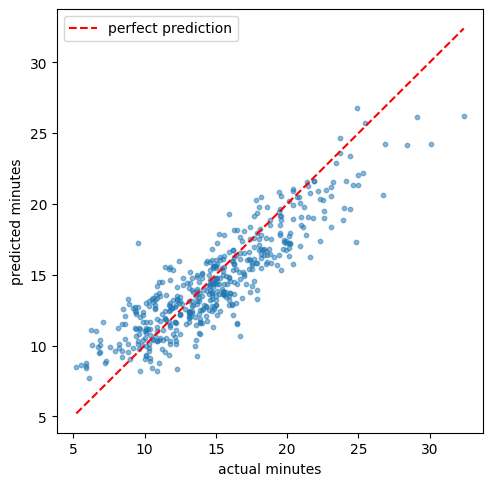

            n   MAE  bias
actual                   
(0, 10]    61  2.33  2.25
(10, 15]  209  1.29 -0.04
(15, 20]  147  1.69 -1.19
(20, 25]   54  2.33 -2.17
(25, 40]    8  3.92 -3.85
         size   mean
raining             
0         381  1.675
1          98  1.835
            size   mean
order_hour             
False        340  1.725
True         139  1.664
      actual   pred  distance_km  store_queue  raining  order_hour
2164     9.5  17.24         0.36          2.0        1          22
800     24.8  17.34         2.28         11.0        0           9
303     32.4  26.21         4.84          1.0        1          12
1805    26.7  20.67         3.93          3.0        0          16
177     16.7  10.69         0.85          1.0        0          12


In [13]:
import matplotlib.pyplot as plt

# ---------- Q16: predicted vs actual ----------
err = pd.DataFrame({"actual": y_test, "pred": pred}, index=y_test.index).join(X_test)
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["signed"]  = err["pred"] - err["actual"]      # + = model too slow, - = model too fast

# plot
plt.figure(figsize=(5.5, 5.5))
plt.scatter(err["actual"], err["pred"], s=10, alpha=.5)
lim = [err["actual"].min(), err["actual"].max()]
plt.plot(lim, lim, "r--", label="perfect prediction")
plt.xlabel("actual minutes"); plt.ylabel("predicted minutes"); plt.legend()
plt.show()

# where are the errors biggest?
print(err.groupby(pd.cut(err["actual"], [0, 10, 15, 20, 25, 40]), observed=True)
         .agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("signed", "mean")).round(2))

# rain vs no rain
print(err.groupby("raining")["abs_err"].agg(["size", "mean"]).round(3))

# peak (18:00-21:59) vs the rest
print(err.groupby(err["order_hour"].between(18, 21))["abs_err"].agg(["size", "mean"]).round(3))

# the five worst predictions
print(err.sort_values("abs_err", ascending=False).head(5)
         [["actual","pred","distance_km","store_queue","raining","order_hour"]].round(2))

In [14]:
for b in [0, 2, 3, 4, 5]:
    print(b, (y_test.values > pred + b).mean())


0 0.6033402922755741
2 0.21920668058455114
3 0.09812108559498957
4 0.03966597077244259
5 0.014613778705636743


In [15]:
new = pd.DataFrame([dict(distance_km=2.4, items=12, order_value_rs=1450, store_queue=11,
                         raining=1, rider_experience_months=3, drop_floor=14, order_hour=20)])[feats]
p_new = best.predict(new)[0]; print(p_new, p_new + 3)

23.767284768951964 26.767284768951964


In [16]:
Z = best["sc"].transform(best["imp"].transform(new))
dist, idx = best["knn"].kneighbors(Z)
print(df.loc[X_train.index[idx[0]], ["store","order_hour","distance_km","items",
      "store_queue","raining","delivery_minutes"]].assign(dist=dist[0].round(2)))

         store  order_hour  distance_km  items  store_queue  raining  \
1031     Vashi          19         2.64      9         11.0        1   
864   Kharghar          18         1.60     10          9.0        1   
1580     Nerul          18         1.23     13         11.0        1   
1425     Nerul          19         1.77     11         13.0        1   
665     Panvel          23         1.69     11          7.0        1   
2115  Kharghar          17         2.44     10          7.0        1   
739   Kharghar          21         2.84      9         10.0        1   

      delivery_minutes  dist  
1031              28.4  1.70  
864               21.5  1.76  
1580              21.2  1.97  
1425              23.9  2.03  
665               22.3  2.16  
2115              22.7  2.19  
739               26.1  2.39  


In [17]:
new0 = new.assign(raining=0); print(p_new, best.predict(new0)[0])

23.767284768951964 19.51158260767676


In [18]:
flat = (y_test > 15).mean(); model = (y_test.values > pred + 3).mean()
print(flat, model, (flat - model) * 1000 * 50)

NameError: name 'flat' is not defined

In [19]:
# ---------- Q21: flat "15 minutes" vs model + buffer ----------
BUFFER, COUPON = 3, 50

late_flat  = (y_test.values > 15).mean()                    # today's flat promise
promise    = pred + BUFFER                                  # model's promise per order
late_model = (y_test.values > promise).mean()

saving_per_1000 = (late_flat - late_model) * 1000 * COUPON

print(f"Late under flat 15 min      : {late_flat:.1%}  ({late_flat*1000:.0f} per 1000 orders)")
print(f"Late under model + {BUFFER} min     : {late_model:.1%}  ({late_model*1000:.0f} per 1000 orders)")
print(f"Coupon cost per 1000 orders : flat Rs {late_flat*1000*COUPON:,.0f}  vs  model Rs {late_model*1000*COUPON:,.0f}")
print(f"Saving per 1000 orders      : Rs {saving_per_1000:,.0f}")
print(f"Average promise shown       : {promise.mean():.1f} min  (share of promises <= 15 min: {(promise<=15).mean():.0%})")

NameError: name 'promise' is not defined